In [1]:
import numpy as np

np.random.seed(42)

X = np.linspace(50, 200, 100).reshape(-1, 1)
y = 50 * X.squeeze() + 1000 + np.random.normal(0, 500, 100)

print("شکل X:", X.shape)
print("شکل y:", y.shape)
print("۵ نمونه اول X:", X[:5].flatten())
print("۵ نمونه اول y:", y[:5])

شکل X: (100, 1)
شکل y: (100,)
۵ نمونه اول X: [50.         51.51515152 53.03030303 54.54545455 56.06060606]
۵ نمونه اول y: [3748.35707651 3506.62542517 3975.35942057 4488.78765548 3685.95361567]


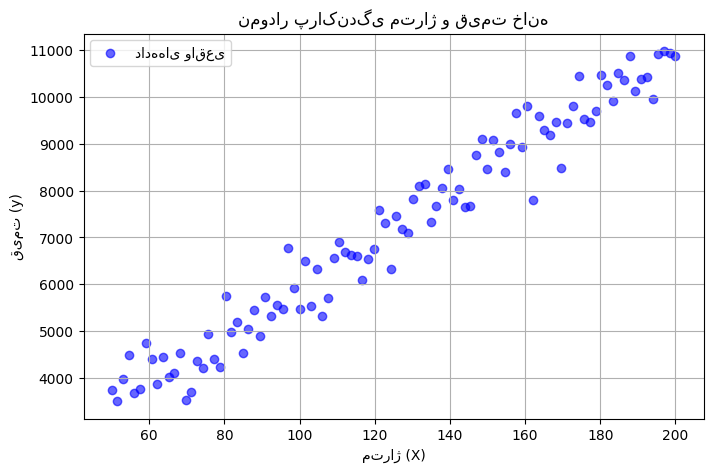

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, label='داده‌های واقعی')
plt.xlabel('متراژ (X)')
plt.ylabel('قیمت (y)')
plt.title('نمودار پراکندگی متراژ و قیمت خانه')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# --- روش ۱: پیاده‌سازی دستی با فرمول کمترین مربعات ---
x_flat = X.squeeze()
x_mean = x_flat.mean()
y_mean = y.mean()

w_manual = np.sum((x_flat - x_mean) * (y - y_mean)) / np.sum((x_flat - x_mean)**2)
b_manual = y_mean - w_manual * x_mean

print("=== مدل دستی (کمترین مربعات) ===")
print(f"w (شیب): {w_manual:.4f}")
print(f"b (عرض از مبدأ): {b_manual:.4f}")
print(f"معادله: y = {w_manual:.2f} * x + {b_manual:.2f}")

# --- روش ۲: مدل آماده با scikit-learn ---
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

print("\n=== مدل scikit-learn ===")
print(f"w (شیب): {model.coef_[0]:.4f}")
print(f"b (عرض از مبدأ): {model.intercept_:.4f}")
print(f"معادله: y = {model.coef_[0]:.2f} * x + {model.intercept_:.2f}")

=== مدل دستی (کمترین مربعات) ===
w (شیب): 50.4598
b (عرض از مبدأ): 890.6048
معادله: y = 50.46 * x + 890.60

=== مدل scikit-learn ===
w (شیب): 50.4598
b (عرض از مبدأ): 890.6048
معادله: y = 50.46 * x + 890.60


In [4]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# پیش‌بینی روی همان داده آموزشی
y_pred = model.predict(X)

# محاسبه معیارهای خطا
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("=== ارزیابی مدل ===")
print(f"MSE  (میانگین مربعات خطا): {mse:,.2f}")
print(f"RMSE (ریشه میانگین مربعات خطا): {rmse:,.2f}")
print(f"MAE  (میانگین قدرمطلق خطا): {mae:,.2f}")
print(f"R²   (ضریب تعیین): {r2:.4f}")

# نمایش ۵ نمونه از پیش‌بینی‌ها در برابر مقادیر واقعی
print("\n=== نمونه پیش‌بینی در برابر واقعیت ===")
for i in range(5):
    print(f"x={X[i][0]:.1f} | واقعی={y[i]:.1f} | پیش‌بینی={y_pred[i]:.1f} | خطا={y[i]-y_pred[i]:.1f}")

=== ارزیابی مدل ===
MSE  (میانگین مربعات خطا): 203,726.18
RMSE (ریشه میانگین مربعات خطا): 451.36
MAE  (میانگین قدرمطلق خطا): 357.48
R²   (ضریب تعیین): 0.9599

=== نمونه پیش‌بینی در برابر واقعیت ===
x=50.0 | واقعی=3748.4 | پیش‌بینی=3413.6 | خطا=334.8
x=51.5 | واقعی=3506.6 | پیش‌بینی=3490.0 | خطا=16.6
x=53.0 | واقعی=3975.4 | پیش‌بینی=3566.5 | خطا=408.9
x=54.5 | واقعی=4488.8 | پیش‌بینی=3643.0 | خطا=845.8
x=56.1 | واقعی=3686.0 | پیش‌بینی=3719.4 | خطا=-33.5


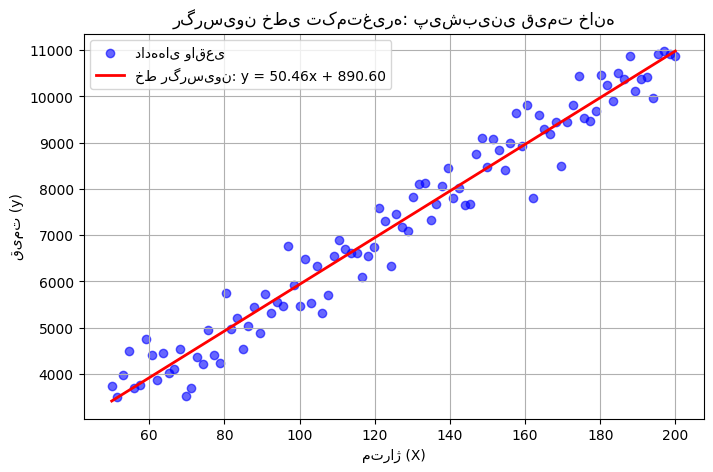

=== جمع‌بندی ===
مدل نهایی: y = 50.46 * x + 890.60
مقدار واقعی مسئله: y = 50 * x + 1000
خطای RMSE: 451.36 (نویز داده: انحراف معیار 500)
R²: 0.9599
نتیجه: مدل رابطه خطی را با دقت بالا کشف کرد و خطای باقی‌مانده در حد نویز داده است.


In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.6, label='داده‌های واقعی')

# خط رگرسیون: از کمترین تا بیشترین x
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

plt.plot(x_line, y_line, color='red', linewidth=2,
         label=f'خط رگرسیون: y = {model.coef_[0]:.2f}x + {model.intercept_:.2f}')

plt.xlabel('متراژ (X)')
plt.ylabel('قیمت (y)')
plt.title('رگرسیون خطی تک‌متغیره: پیش‌بینی قیمت خانه')
plt.legend()
plt.grid(True)
plt.show()

# جمع‌بندی نهایی
print("=== جمع‌بندی ===")
print(f"مدل نهایی: y = {model.coef_[0]:.2f} * x + {model.intercept_:.2f}")
print(f"مقدار واقعی مسئله: y = 50 * x + 1000")
print(f"خطای RMSE: {451.36:.2f} (نویز داده: انحراف معیار 500)")
print(f"R²: {0.9599:.4f}")
print("نتیجه: مدل رابطه خطی را با دقت بالا کشف کرد و خطای باقی‌مانده در حد نویز داده است.")